# Softmax attention experiments

# My Custom Experiments

In the previous sections I have attempted to re-produce experiments from Gatmiry et al. In the following sections, I will implement several experiments that apply different assumptions and test the theoretical bounds of this paper. These were not written in the original paper.

In [1]:
# Imports and setup

import torch
from matplotlib import pyplot as plt
import os
import numpy as np

from experiments_helper import (
    run_experiment_suite,
    compute_loss_dict,
    compute_looped_loss_by_loop_count,
    compute_dist_dict,
    plot_loss_curves,
    plot_parameter_matrices,
    plot_dist_to_identity,
    plot_loop_loss_curves,
)

np.set_printoptions(precision=2, suppress=True)
torch.set_printoptions(precision=2)

log_dir = 'log'
cur_dir = log_dir
os.makedirs(cur_dir, exist_ok=True)

In [2]:
# Problem parameters (defined in experiments_helper.py; edit them there so the
# helper functions see the same values)

from experiments_helper import (
    device, lr, alg, normal_data_mode, N, d, B, var,
    max_iters, hist_stride, stride, TEST_SEED,
)

print(f'Running on device: {device}.')

Running on device: cuda.


In [3]:
softmax_attention_types = ['linear', 'softmax']
softmax_seeds = [0, 1, 2]
softmax_counts = [5]
softmax_model_types = ['looped']
softmax_context_lengths = [N]
softmax_data_modes = [normal_data_mode]
softmax_head_counts = [1, 2]
softmax_iterations = np.arange(0, max_iters, stride)

In [ ]:
# Final experiment: repeat the layered/looped sweep with linear and softmax attention.
# This uses the same seeds, counts, data mode, optimizer, training steps, and
# reusable loss/distance/parameter plotting helpers as the baseline experiment.
# Each configuration is trained with both attention types and with 1 and 2 heads.

softmax_fig_dir = os.path.join('figures', 'softmax_attention')
os.makedirs(softmax_fig_dir, exist_ok=True)
softmax_heads_tag = '-'.join(str(head_count) for head_count in softmax_head_counts)
softmax_attention_tag = '-'.join(softmax_attention_types)
softmax_history_file = os.path.join(
    cur_dir,
    f'softmax_attention_N{N}_d{d}_heads{softmax_heads_tag}_attn-{softmax_attention_tag}_histories.pth')
softmax_results_file = os.path.join(
    cur_dir,
    f'softmax_attention_N{N}_d{d}_heads{softmax_heads_tag}_attn-{softmax_attention_tag}_results.pth')

softmax_hist_dict = run_experiment_suite(
    seeds=softmax_seeds,
    n_layers_loops=softmax_counts,
    model_types=softmax_model_types,
    filename=softmax_history_file,
    context_lengths=softmax_context_lengths,
    data_modes=softmax_data_modes,
    head_counts=softmax_head_counts,
    attention_types=softmax_attention_types,
    freeze_p=True,  # [P-FIX] paper's P = [[0, 0], [0, 1]]
)
softmax_loss_dict = compute_loss_dict(
    softmax_hist_dict,
    test_seed=TEST_SEED,
    attention_types=softmax_attention_types,
)


def filter_by_head_count(run_dict, head_count):
    """Keep only the runs in `run_dict` trained with `head_count` heads (key[5])."""
    return {key: value for key, value in run_dict.items() if key[5] == head_count}


# Distance-to-identity has to be computed per head count, since the number of
# heads determines how many P/Q blocks are averaged for each checkpoint.
softmax_dist_dicts = {
    head_count: compute_dist_dict(
        filter_by_head_count(softmax_hist_dict, head_count),
        softmax_iterations,
        n_head=head_count,
        hist_stride=hist_stride,
    )
    for head_count in softmax_head_counts
}

torch.save(
    {
        'config': {
            'N': N, 'd': d, 'B': B, 'head_counts': softmax_head_counts,
            'attention_types': softmax_attention_types,
            'data_modes': softmax_data_modes,
            'seeds': softmax_seeds, 'counts': softmax_counts,
            'model_types': softmax_model_types,
            'alg': alg, 'lr': lr, 'var': var,
            'max_iters': max_iters, 'hist_stride': hist_stride,
            'stride': stride, 'test_seed': TEST_SEED,
        },
        'history_file': softmax_history_file,
        'hist_dict': softmax_hist_dict,
        'loss_dict': softmax_loss_dict,
        'distance_dicts': softmax_dist_dicts,
        'iterations': softmax_iterations,
    },
    softmax_results_file,
)
print(f'Saved softmax-attention experiment results to {softmax_results_file}')

Run 1/12: seed=0, count=5, type=looped, N=20, mode=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear, freeze_p=True, learn_u=False
iter 0 | Loss: 5.276184558868408 | time: 0.23604369163513184 | gradnorm: 24.04814338684082
iter 1 | Loss: 5.0252580642700195 | time: 0.01137399673461914 | gradnorm: 22.60677719116211
iter 2 | Loss: 4.86858606338501 | time: 0.010318756103515625 | gradnorm: 21.61155891418457
iter 3 | Loss: 4.762965679168701 | time: 0.010233402252197266 | gradnorm: 21.015846252441406
iter 4 | Loss: 4.888327598571777 | time: 0.010796546936035156 | gradnorm: 22.025737762451172
iter 100 | Loss: 2.027477264404297 | time: 0.01028752326965332 | gradnorm: 7.594679832458496
iter 200 | Loss: 0.9559585452079773 | time: 0.010040283203125 | gradnorm: 2.9032771587371826
iter 300 | Loss: 0.5201327800750732 | time: 0.010023355484008789 | gradnorm: 1.3552889823913574
iter 400 | Loss: 0.32646530866622925 | time: 0.010009288787841797 

In [4]:
# Load the saved softmax/linear attention results instead of retraining.
# Run this cell in place of the training cell above; it restores every variable
# the plotting cells below use. The file name is rebuilt from these settings, so
# change them to load a different run.
softmax_N, softmax_d = N, d
softmax_head_counts = [1, 2]
softmax_attention_types = ['linear', 'softmax']
softmax_heads_tag = '-'.join(str(head_count) for head_count in softmax_head_counts)
softmax_attention_tag = '-'.join(softmax_attention_types)
softmax_results_file = os.path.join(
    cur_dir,
    f'softmax_attention_N{softmax_N}_d{softmax_d}_heads{softmax_heads_tag}'
    f'_attn-{softmax_attention_tag}_results.pth')

# weights_only=False is needed because the file stores DataMode objects and
# numpy arrays, not just tensors. Only load result files you created yourself.
softmax_results = torch.load(softmax_results_file, map_location='cpu', weights_only=False)

softmax_config = softmax_results['config']
softmax_history_file = softmax_results['history_file']
softmax_hist_dict = softmax_results['hist_dict']
softmax_loss_dict = softmax_results['loss_dict']
softmax_dist_dicts = softmax_results['distance_dicts']
softmax_iterations = softmax_results['iterations']

# Experiment settings, taken from the saved config so they match the loaded runs.
softmax_head_counts = softmax_config['head_counts']
softmax_attention_types = softmax_config['attention_types']
softmax_data_modes = softmax_config['data_modes']
softmax_seeds = softmax_config['seeds']
softmax_counts = softmax_config['counts']
softmax_model_types = softmax_config['model_types']
softmax_context_lengths = [softmax_config['N']]
hist_stride = softmax_config['hist_stride']

softmax_fig_dir = os.path.join('figures', 'softmax_attention')
os.makedirs(softmax_fig_dir, exist_ok=True)


def filter_by_head_count(run_dict, head_count):
    """Keep only the runs in `run_dict` trained with `head_count` heads (key[5])."""
    return {key: value for key, value in run_dict.items() if key[5] == head_count}


# Warn if the saved run used different global settings from experiments_helper.py.
for name, current in {'d': d, 'B': B, 'var': var, 'lr': lr, 'alg': alg,
                      'max_iters': max_iters, 'stride': stride, 'test_seed': TEST_SEED}.items():
    if softmax_config[name] != current:
        print(f'Warning: saved {name}={softmax_config[name]!r} differs from current {name}={current!r}.')

print(f'Loaded {len(softmax_hist_dict)} runs from {softmax_results_file}')
print('Saved config:', softmax_config)

Loaded 12 runs from log/softmax_attention_N20_d5_heads1-2_attn-linear-softmax_results.pth
Saved config: {'N': 20, 'd': 5, 'B': 4000, 'head_counts': [1, 2], 'attention_types': ['linear', 'softmax'], 'data_modes': [DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None)], 'seeds': [0, 1, 2], 'counts': [5], 'model_types': ['looped'], 'alg': 'adam', 'lr': 0.001, 'var': 0.0001, 'max_iters': 10000, 'hist_stride': 1, 'stride': 100, 'test_seed': 99}


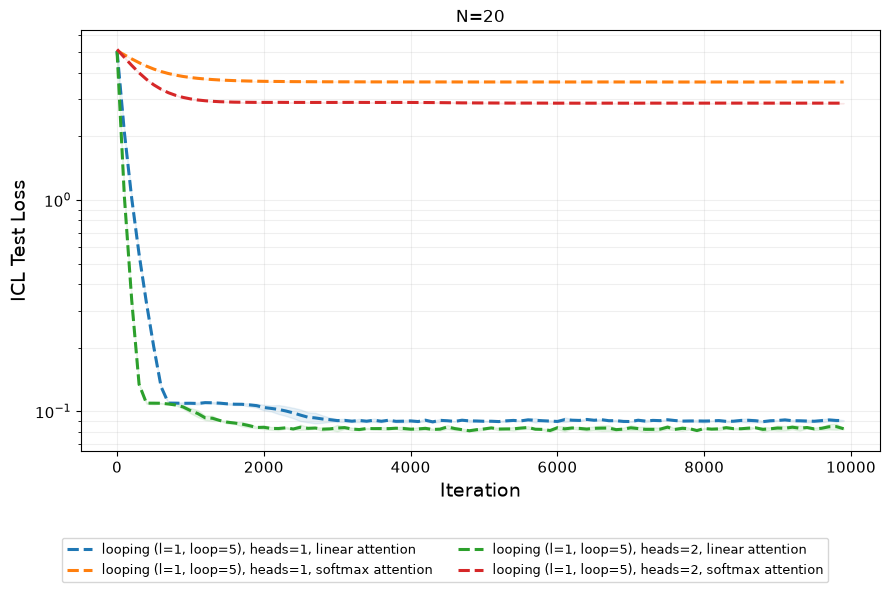

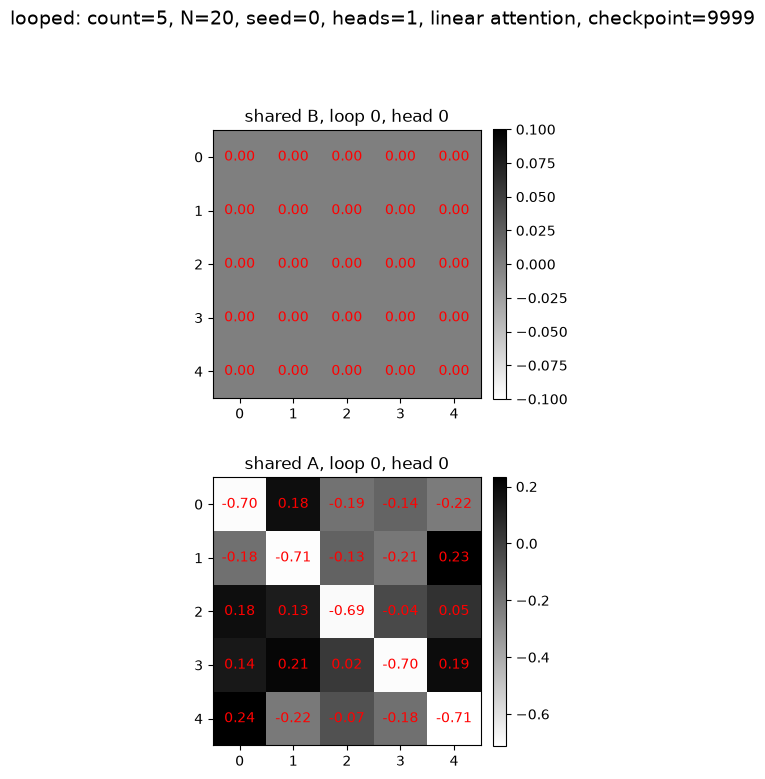

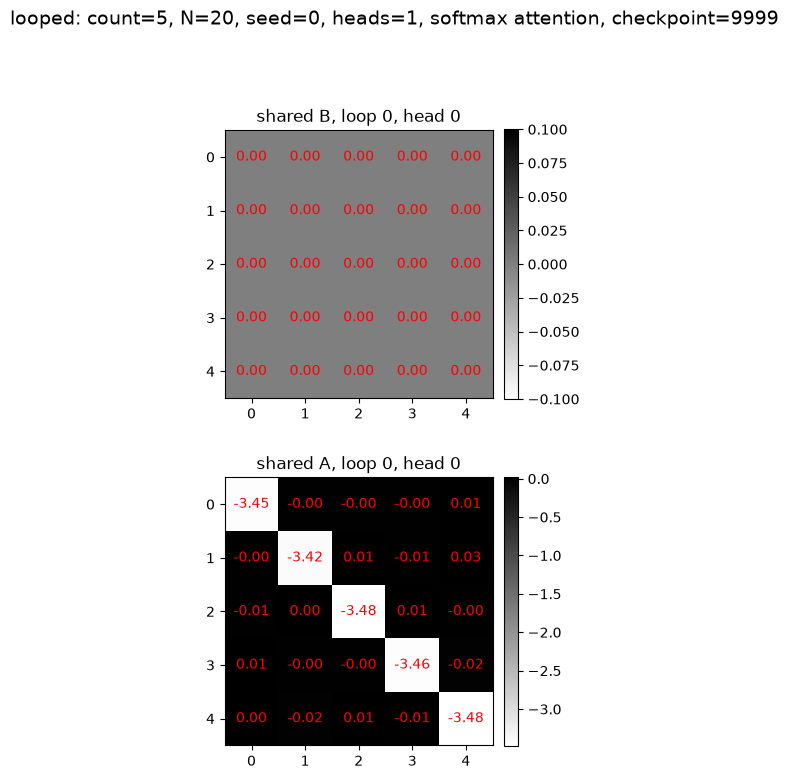

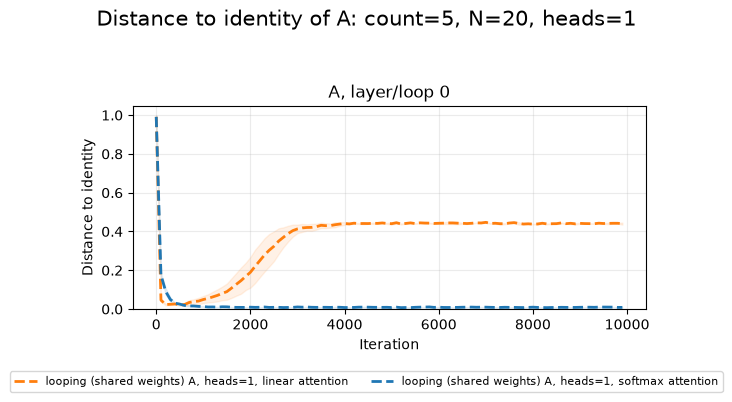

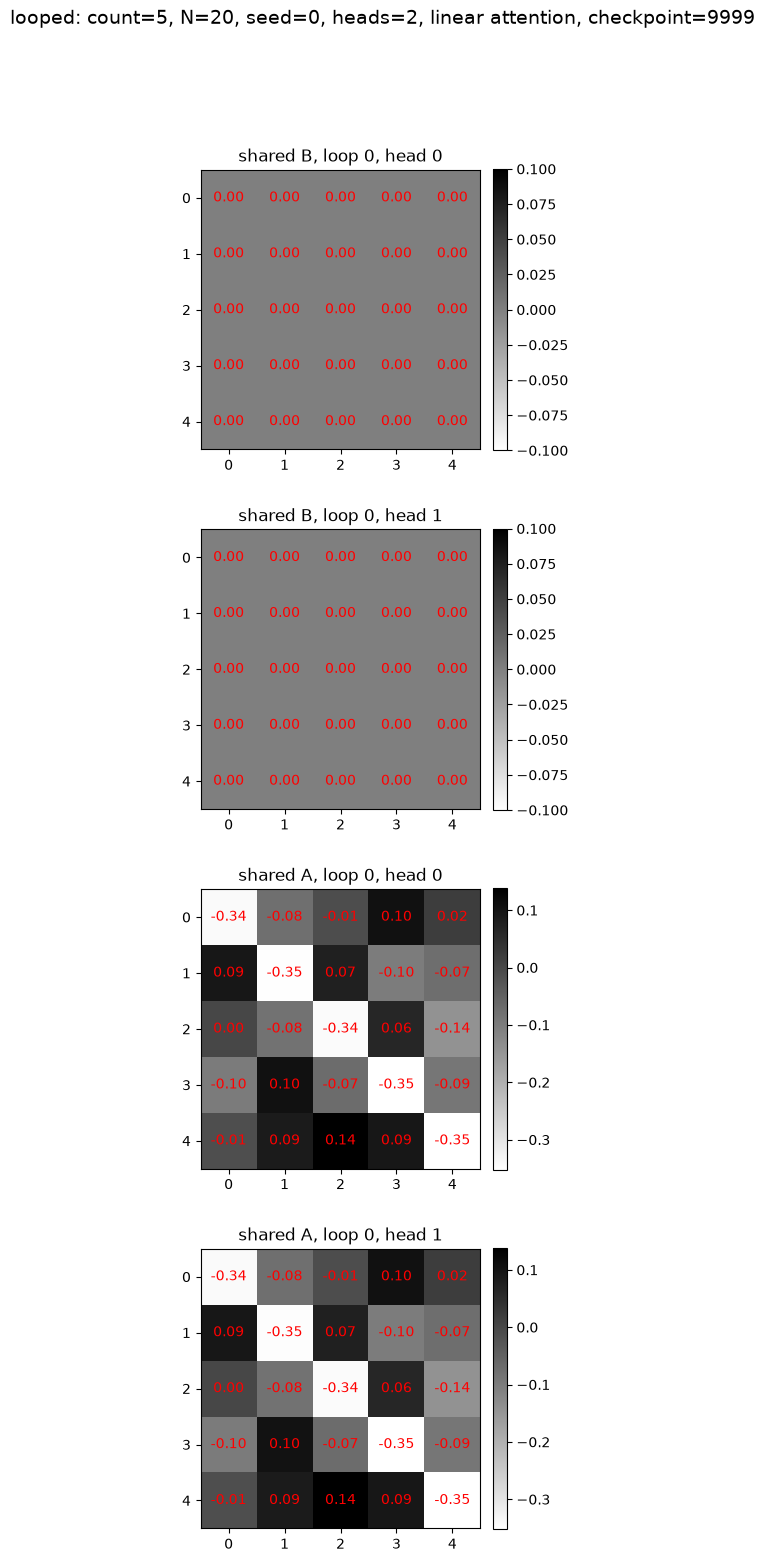

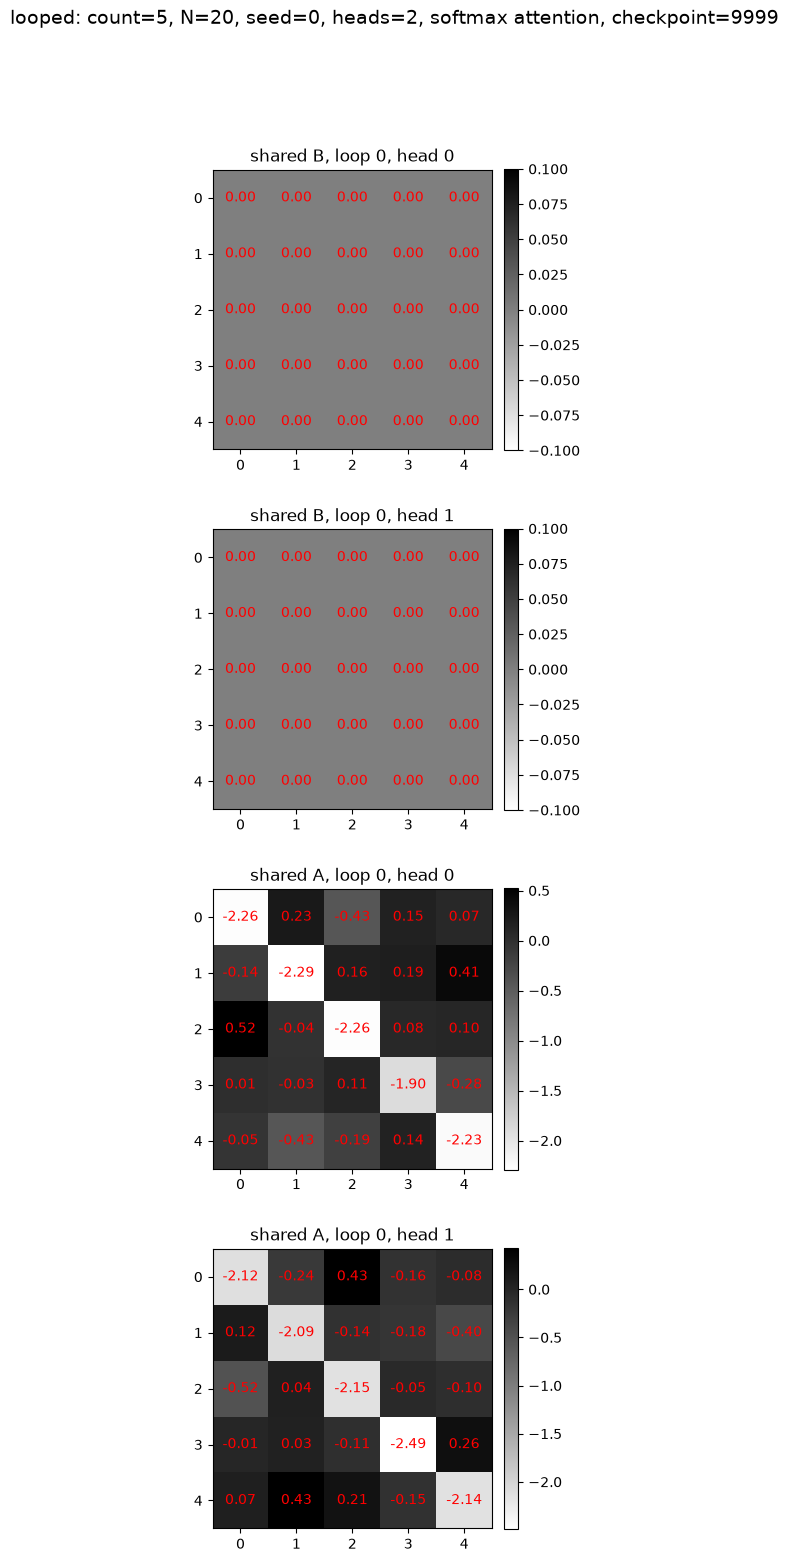

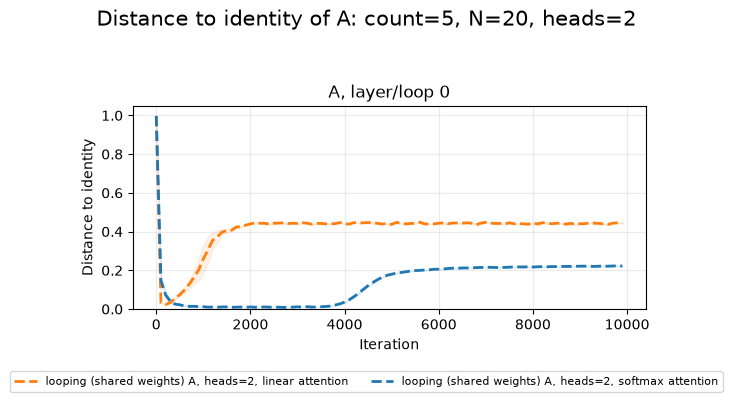

In [5]:
# Loss curves for every (head count, attention type) pair, plotted together on one
# graph; each pair gets its own color and is labeled with its heads and attention type.
plot_loss_curves(
    softmax_loss_dict,
    softmax_counts,
    softmax_model_types,
    softmax_iterations,
    fig_dir=softmax_fig_dir,
    filename=f'softmax_test_loss_heads-{softmax_heads_tag}_attn-{softmax_attention_tag}.pdf',
    head_counts=softmax_head_counts,
    attention_types=softmax_attention_types,
    labels=['heads', 'attention'],
)

# Parameter matrices (one figure per attention type, labeled in the title) and
# distance to identity (both attention types on one labeled graph) per head count.
for head_count in softmax_head_counts:
    head_fig_dir = os.path.join(softmax_fig_dir, f'{head_count}_heads')
    os.makedirs(head_fig_dir, exist_ok=True)
    head_hist_dict = filter_by_head_count(softmax_hist_dict, head_count)

    plot_parameter_matrices(
        head_hist_dict,
        softmax_seeds[0],
        softmax_counts,
        softmax_model_types,
        n_head=head_count,
        hist_stride=hist_stride,
        fig_dir=head_fig_dir,
        head_count=head_count,
        labels=['heads', 'attention'],
    )
    plot_dist_to_identity(
        softmax_dist_dicts[head_count],
        softmax_counts,
        softmax_iterations,
        fig_dir=head_fig_dir,
        head_count=head_count,
        labels=['heads', 'attention'],
    )

Testing: (0, 5, 'looped', 20, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1, 'softmax')
Evaluated checkpoint (0, 5, 'looped', 20, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1, 'softmax') through 50 loops.
Testing: (0, 5, 'looped', 20, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 2, 'softmax')
Evaluated checkpoint (0, 5, 'looped', 20, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 2, 'softmax') through 50 loops.
Testing: (1, 5, 'looped', 20, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1, 'softmax')
Evaluated checkpoint (1, 5, 'looped', 20, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1, 'softmax') through 50 loops.
Testing: (1, 5, 'looped', 20, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 2, 'softmax')
Evaluat

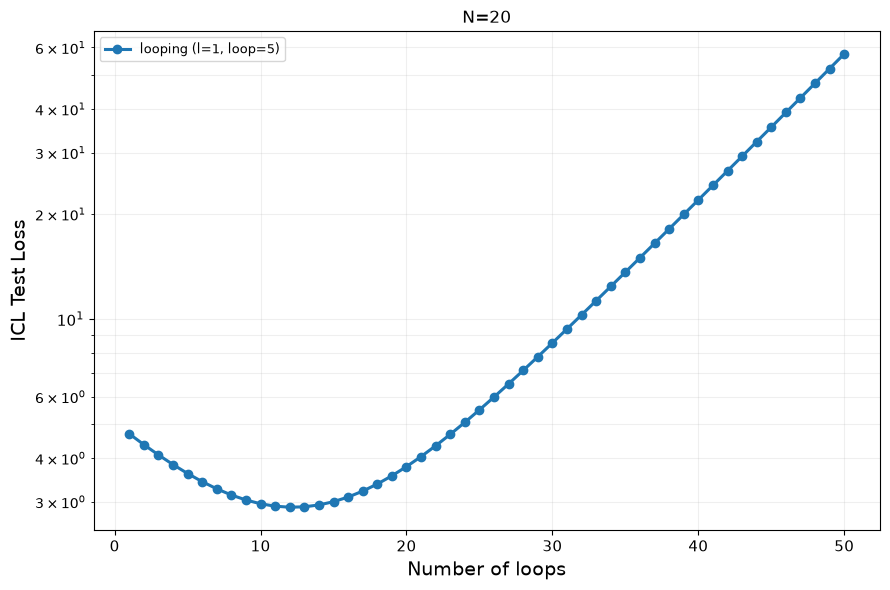

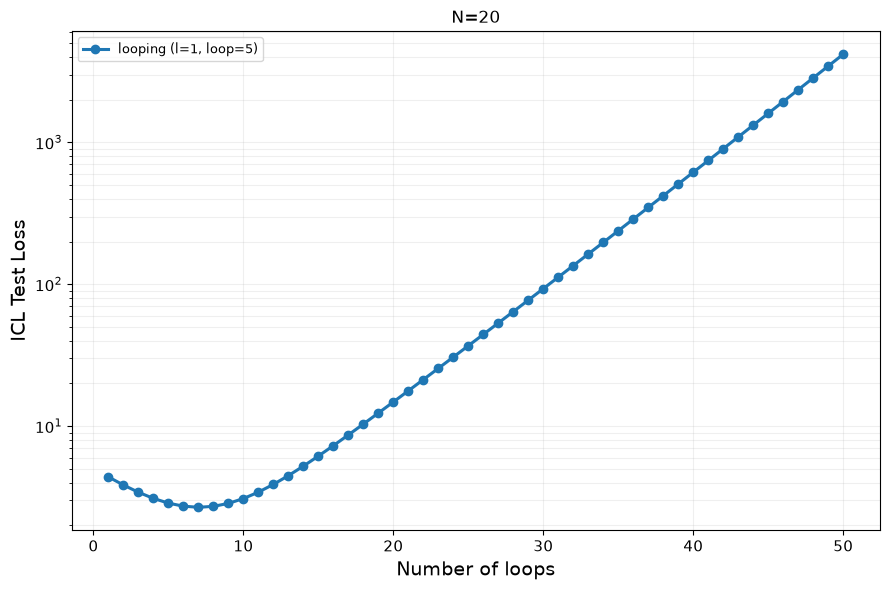

Saved softmax loop-count results to log/softmax_attention_loop_count_N20_d5_heads1-2_results.pth


In [6]:
# Evaluate final softmax looped checkpoints with 1 through 50 inference loops,
# separately for each head count.
softmax_looped_hist_dict = {
    key: history
    for key, history in softmax_hist_dict.items()
    if key[2] == 'looped' and key[-1] == 'softmax'
}

softmax_max_loops = 50
softmax_loop_loss_dict = compute_looped_loss_by_loop_count(
    softmax_looped_hist_dict,
    max_loops=softmax_max_loops,
    test_seed=TEST_SEED,
    attention_type='softmax',
)

softmax_loop_results_file = os.path.join(
    cur_dir,
    f'softmax_attention_loop_count_N{N}_d{d}_heads{softmax_heads_tag}_results.pth',
)
torch.save({
    'max_loops': softmax_max_loops,
    'test_seed': TEST_SEED,
    'attention_type': 'softmax',
    'head_counts': softmax_head_counts,
    'loss_dict': softmax_loop_loss_dict,
}, softmax_loop_results_file)

for head_count in softmax_head_counts:
    head_fig_dir = os.path.join(softmax_fig_dir, f'{head_count}_heads')
    os.makedirs(head_fig_dir, exist_ok=True)
    plot_loop_loss_curves(
        filter_by_head_count(softmax_loop_loss_dict, head_count),
        n_layers_loops=softmax_counts,
        loop_counts=range(1, softmax_max_loops + 1),
        fig_dir=head_fig_dir,
        filename=f'softmax_test_loss_vs_loop_count_heads-{head_count}.pdf',
    )
print(f'Saved softmax loop-count results to {softmax_loop_results_file}')